# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer: My starting guess is that a first-class girl traveling with family would have a better chance, while an adult man in third class without parents or children aboard would have a worse chance. That is based on the idea of women and children being helped first and possible differences in access to lifeboats. I do not have a strong starting guess for the port or exact number of siblings.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)


In [2]:
titanic_df = pd.read_csv("data/titanic_passengers.csv")


In [3]:
titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
titanic_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [5]:
titanic_df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer: Each row is one passenger in this 891-row file, not the full passenger and crew list. The target is `Survived`. A 0 means the passenger did not survive, and a 1 means they survived.


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | str | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | str | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative count, grouped into categories below | int64 | 0 |
| `SibSp` | Quantitative count, grouped into categories below | int64 | 0 |
| `Embarked` | Categorical | str | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child | Known age below 16 years | A simple group for younger passengers |
| Adult | Known age of 16 years or more | Keeps the cutoff clear, including age 16 |
| Unknown | Age is missing | Keeps missing ages separate without guessing |


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer: A split at 16 gives a simple comparison of younger and older passengers. It is a choice for this lab, not a claim about the legal adult age in 1912. Missing ages stay in Unknown and are kept in the age tables. They will not be treated as adults or used as a character's known age.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
titanic_df["age_group"] = "Unknown"
titanic_df.loc[titanic_df["Age"] < 16, "age_group"] = "Child"
titanic_df.loc[titanic_df["Age"] >= 16, "age_group"] = "Adult"
titanic_df["age_group"].value_counts()


age_group
Adult      631
Unknown    177
Child       83
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer: There are 83 children, 631 adults, and 177 unknown ages. The child group is smaller, but still large enough for this basic comparison. I will keep these groups. The 177 unknown ages are a bigger concern because they leave out useful age information.


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
titanic_df["Parch"].value_counts().sort_index()


Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

In [8]:
titanic_df["SibSp"].value_counts().sort_index()


SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

In [9]:
titanic_df["parch_group"] = "None"
titanic_df.loc[titanic_df["Parch"] > 0, "parch_group"] = "Any"
titanic_df["parch_group"].value_counts()


parch_group
None    678
Any     213
Name: count, dtype: int64

In [10]:
titanic_df["sibsp_group"] = "None"
titanic_df.loc[titanic_df["SibSp"] == 1, "sibsp_group"] = "One"
titanic_df.loc[titanic_df["SibSp"] >= 2, "sibsp_group"] = "Two or more"
titanic_df["sibsp_group"].value_counts()


sibsp_group
None           608
One            209
Two or more     74
Name: count, dtype: int64

In [11]:
titanic_df["embarked_group"] = titanic_df["Embarked"].map({
    "C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"
})
titanic_df["embarked_group"].value_counts(dropna=False)


embarked_group
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer: For parents or children I use None (0) and Any (1 or more). For siblings or spouse I use None (0), One (1), and Two or more (2 or more). This keeps the groups easy to read and avoids separate bars for counts with very few people. The original columns stay unchanged. The two unknown ports are left out of the port comparison only, leaving 889 passengers there. All other comparisons use all 891 passengers. Each survival percentage divides by every passenger in its own row group, including those who did not survive. None does not mean traveling completely alone.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [12]:
age_counts = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"])
age_counts


Survived,0,1
age_group,,
Adult,390,241
Child,34,49
Unknown,125,52


In [13]:
age_percent = pd.crosstab(
    titanic_df["age_group"], titanic_df["Survived"], normalize="index"
) * 100
age_percent[1].round(2)


age_group
Adult      38.19
Child      59.04
Unknown    29.38
Name: 1, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [14]:
pd.crosstab(
    titanic_df["age_group"], titanic_df["Survived"], normalize="all"
).mul(100).round(2)


Survived,0,1
age_group,,
Adult,43.77,27.05
Child,3.82,5.50
Unknown,14.03,5.84


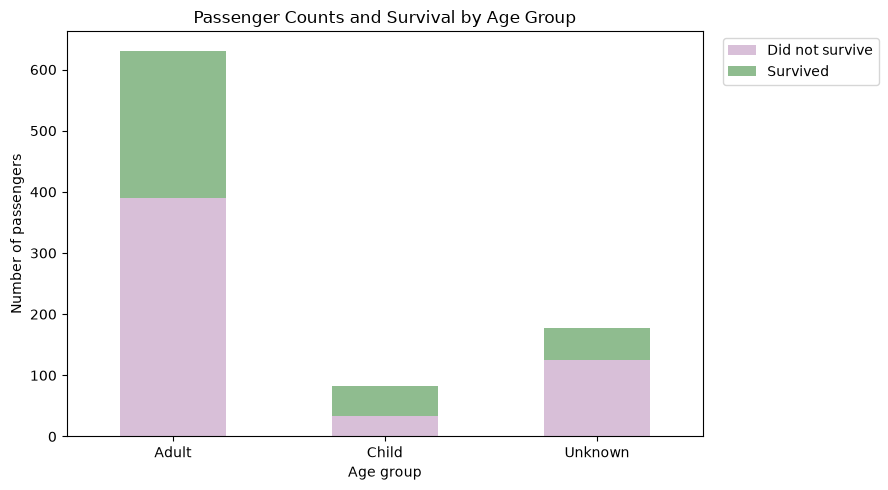

In [15]:
age_counts.plot(kind="bar", stacked=True, color=["thistle", "darkseagreen"], figsize=(9, 5))
plt.title("Passenger Counts and Survival by Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.legend(labels=["Did not survive", "Survived"], loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


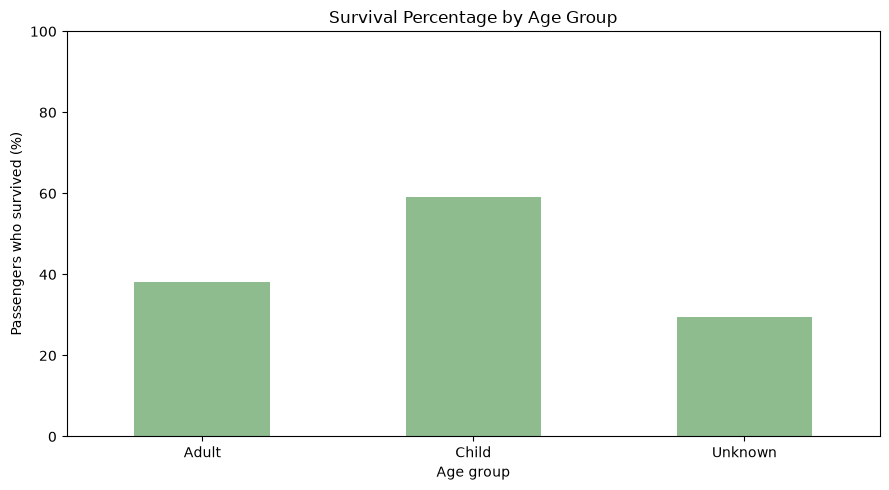

In [16]:
age_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Age Group")
plt.xlabel("Age group")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [17]:
sex_counts = pd.crosstab(titanic_df["Sex"], titanic_df["Survived"])
sex_counts


Survived,0,1
Sex,,
female,81,233
male,468,109


In [18]:
sex_percent = pd.crosstab(
    titanic_df["Sex"], titanic_df["Survived"], normalize="index"
) * 100
sex_percent[1].round(2)


Sex
female    74.20
male      18.89
Name: 1, dtype: float64

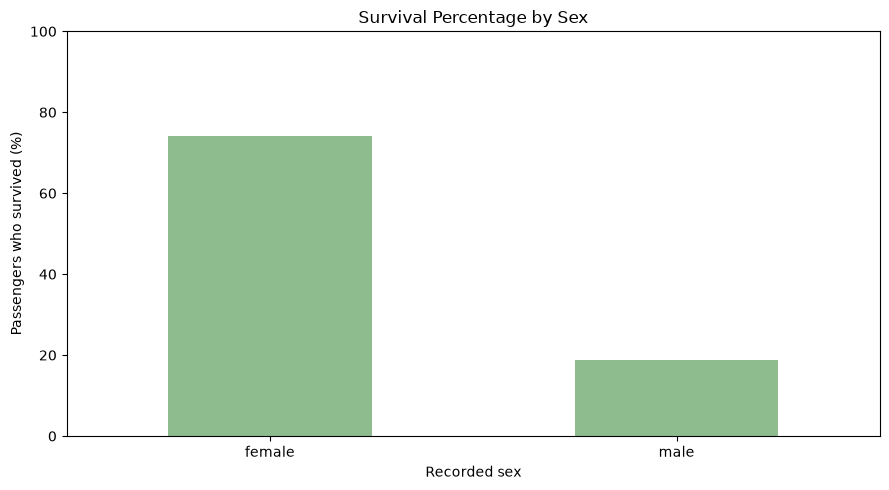

In [19]:
sex_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Sex")
plt.xlabel("Recorded sex")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [20]:
class_counts = pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"])
class_counts


Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [21]:
class_percent = pd.crosstab(
    titanic_df["Pclass"], titanic_df["Survived"], normalize="index"
) * 100
class_percent[1].round(2)


Pclass
1    62.96
2    47.28
3    24.24
Name: 1, dtype: float64

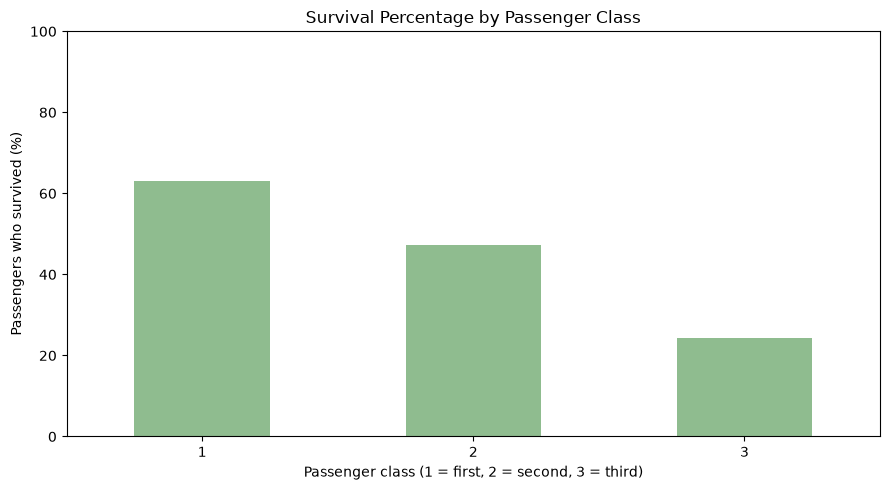

In [22]:
class_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Passenger Class")
plt.xlabel("Passenger class (1 = first, 2 = second, 3 = third)")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [23]:
parch_counts = pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"])
parch_counts


Survived,0,1
parch_group,,
Any,104,109
None,445,233


In [24]:
parch_percent = pd.crosstab(
    titanic_df["parch_group"], titanic_df["Survived"], normalize="index"
) * 100
parch_percent[1].round(2)


parch_group
Any     51.17
None    34.37
Name: 1, dtype: float64

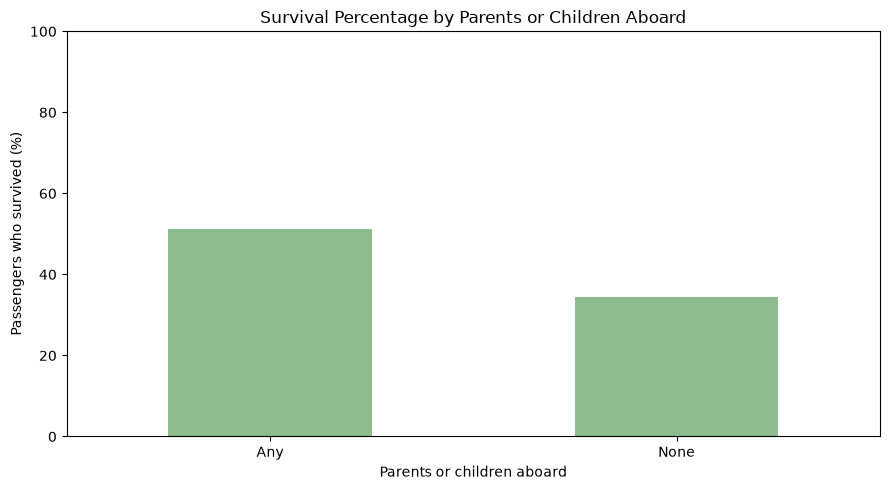

In [25]:
parch_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Parents or Children Aboard")
plt.xlabel("Parents or children aboard")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [26]:
sibsp_counts = pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"])
sibsp_counts


Survived,0,1
sibsp_group,,
None,398,210
One,97,112
Two or more,54,20


In [27]:
sibsp_percent = pd.crosstab(
    titanic_df["sibsp_group"], titanic_df["Survived"], normalize="index"
) * 100
sibsp_percent[1].round(2)


sibsp_group
None           34.54
One            53.59
Two or more    27.03
Name: 1, dtype: float64

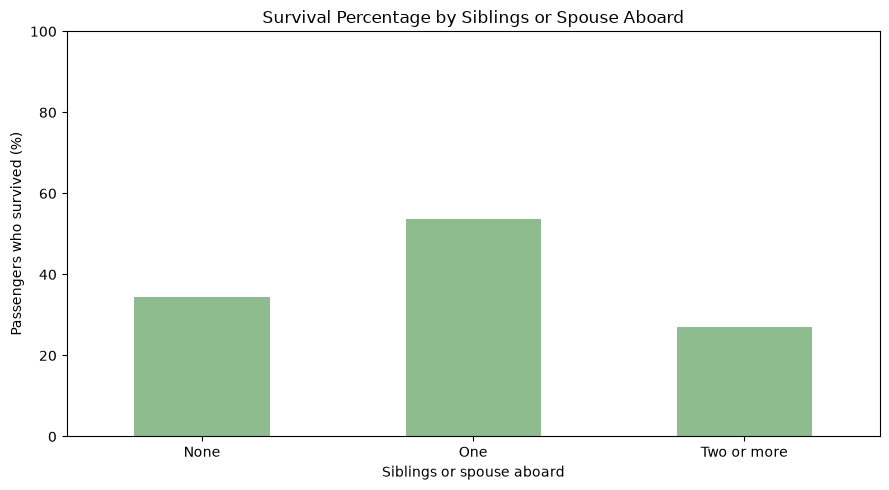

In [28]:
sibsp_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Siblings or Spouse Aboard")
plt.xlabel("Siblings or spouse aboard")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [29]:
port_counts = pd.crosstab(titanic_df["embarked_group"], titanic_df["Survived"])
port_counts


Survived,0,1
embarked_group,,
Cherbourg,75,93
Queenstown,47,30
Southampton,427,217


In [30]:
port_percent = pd.crosstab(
    titanic_df["embarked_group"], titanic_df["Survived"], normalize="index"
) * 100
port_percent[1].round(2)


embarked_group
Cherbourg      55.36
Queenstown     38.96
Southampton    33.70
Name: 1, dtype: float64

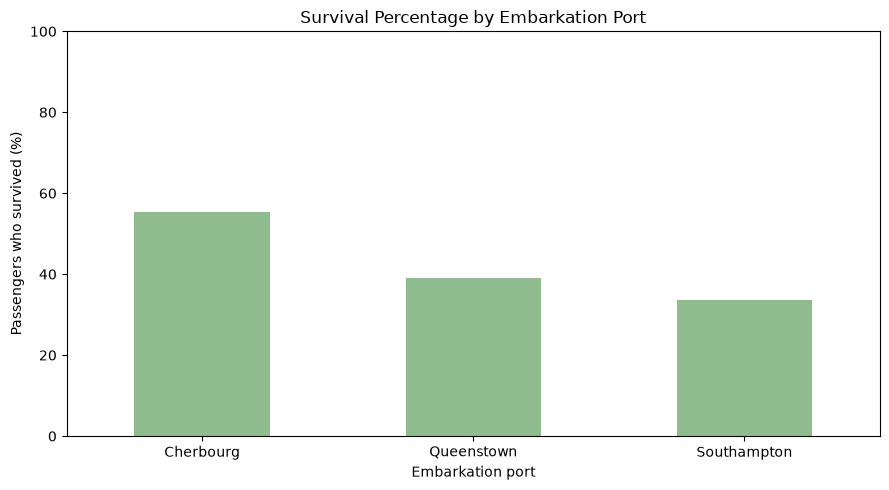

In [31]:
port_percent[1].plot(kind="bar", color="darkseagreen", figsize=(9, 5))
plt.title("Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation port")
plt.ylabel("Passengers who survived (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex | Female: 74.20% (233 of 314) | Male: 18.89% (109 of 577) |
| Age groups | Child: 59.04% (49 of 83) | Unknown: 29.38% (52 of 177). Among known ages, Adult: 38.19% (241 of 631) |
| Passenger class | First: 62.96% (136 of 216) | Third: 24.24% (119 of 491) |
| Parents or children aboard | Any: 51.17% (109 of 213) | None: 34.37% (233 of 678) |
| Siblings or spouse aboard | One: 53.59% (112 of 209) | Two or more: 27.03% (20 of 74) |
| Embarkation port | Cherbourg: 55.36% (93 of 168) | Southampton: 33.70% (217 of 644) |

There are no ties for highest or lowest. The grouped categories have at least 74 passengers. Some original companion counts have only a few people, so those were combined. Unknown age is missing information, not a known personal trait.


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer: 49 of all 891 passengers were children who survived, which is 5.50% jointly. Within the child group, 49 of 83 survived, which is 59.04% conditionally. The survivor-percentage chart answers the survival-likelihood question more clearly because each bar uses its own age group as the denominator. The count chart instead shows how many passengers are in each outcome and age group.


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [32]:
titanic_df.groupby("age_group")["Age"].agg(["count", "min", "max"])


,count,min,max
age_group,,,
Adult,631,16.00,80.0
Child,83,0.42,15.0
Unknown,0,NaN,NaN


In [33]:
titanic_df.loc[titanic_df["Age"] == 16, ["Age", "age_group"]]


,Age,age_group
71,16.0,Adult
86,16.0,Adult
138,16.0,Adult
156,16.0,Adult
208,16.0,Adult
220,16.0,Adult
266,16.0,Adult
282,16.0,Adult
329,16.0,Adult
333,16.0,Adult


In [34]:
pd.crosstab(titanic_df["Age"].isnull(), titanic_df["age_group"])


age_group,Adult,Child,Unknown
Age,,,
False,631,83,0
True,0,0,177


In [35]:
pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"])


parch_group,Any,None
Parch,,
0,0,678
1,118,0
2,80,0
3,5,0
4,4,0
5,5,0
6,1,0


In [36]:
pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"])


sibsp_group,None,One,Two or more
SibSp,,,
0,608,0,0
1,0,209,0
2,0,0,28
3,0,0,16
4,0,0,18
5,0,0,5
8,0,0,7


In [37]:
print("Child survivor percentage:", round(age_counts.loc["Child", 1] / age_counts.loc["Child"].sum() * 100, 2))
print("Passengers in each port group:")
print(port_counts.sum(axis=1))
print("Total passengers in port comparison:", port_counts.sum().sum())


Child survivor percentage: 59.04
Passengers in each port group:
embarked_group
Cherbourg      168
Queenstown      77
Southampton    644
dtype: int64
Total passengers in port comparison: 889


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer: The checks match the rules. Children range from 0.42 to 15 years, adults from 16 to 80, and all 177 missing ages stay Unknown. Age 16 is Adult. The companion tables map 0 to None, positive Parch values to Any, and SibSp values of 2 or more to Two or more. The child percentage is 49 divided by 83, not by 49 or 891. Port totals add to 889 because two ports are missing. A child age of 16, a missing age labeled Adult, or percentages outside 0 to 100 would be warning signs. No coding issue appeared in these checks. Some original high companion counts have very few passengers, and the two missing ports cannot support a useful group comparison.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex | Female: 74.20% (233 of 314) | Male: 18.89% (109 of 577) |
| Age groups | Adult: 38.19% (241 of 631). Revised from Child to obtain real matches | Adult: 38.19% (241 of 631). Lower than Child among known ages |
| Passenger class | First: 62.96% (136 of 216) | Third: 24.24% (119 of 491) |
| Parents or children aboard | Any: 51.17% (109 of 213) | None: 34.37% (233 of 678) |
| Siblings or spouse aboard | One: 53.59% (112 of 209) | Two or more: 27.03% (20 of 74) |
| Embarkation port | Cherbourg: 55.36% (93 of 168) | Southampton: 33.70% (217 of 644) |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer: The higher-survival character is an adult woman in first class, with a parent or child aboard, one sibling or spouse aboard, and a Cherbourg departure. The lower-survival character is an adult man in third class, with no parents or children aboard, at least two siblings or a spouse and sibling aboard, and a Southampton departure. The original higher profile used Child, but no passenger matches all six of those choices. Changing only that age choice to Adult gives real matches. Unknown has the lowest age-group percentage, but I do not use missing age as a character trait. These are higher- and lower-survival profiles based on separate groups, not proven best and worst combinations.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [38]:
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["age_group"] == "Child")
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["parch_group"] == "Any")
    & (titanic_df["sibsp_group"] == "One")
    & (titanic_df["Embarked"] == "C")
]
print("Matches for the original child profile:", len(most_likely_df))


Matches for the original child profile: 0


In [39]:
most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female")
    & (titanic_df["age_group"] == "Adult")
    & (titanic_df["Pclass"] == 1)
    & (titanic_df["parch_group"] == "Any")
    & (titanic_df["sibsp_group"] == "One")
    & (titanic_df["Embarked"] == "C")
]
most_likely_df[["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "parch_group", "SibSp", "sibsp_group", "Embarked"]]


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,parch_group,SibSp,sibsp_group,Embarked
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corning Stone)",female,40.0,Adult,1,1,Any,1,One,C
581,582,"Thayer, Mrs. John Borland (Marian Longstreth Morris)",female,39.0,Adult,1,1,Any,1,One,C
835,836,"Compton, Miss. Sara Rebecca",female,39.0,Adult,1,1,Any,1,One,C


In [40]:
least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male")
    & (titanic_df["age_group"] == "Adult")
    & (titanic_df["Pclass"] == 3)
    & (titanic_df["parch_group"] == "None")
    & (titanic_df["sibsp_group"] == "Two or more")
    & (titanic_df["Embarked"] == "S")
]
least_likely_df[["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "parch_group", "SibSp", "sibsp_group", "Embarked"]]


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,parch_group,SibSp,sibsp_group,Embarked
69,70,"Kink, Mr. Vincenz",male,26.0,Adult,3,0,None,2,Two or more,S
104,105,"Gustafsson, Mr. Anders Vilhelm",male,37.0,Adult,3,0,None,2,Two or more,S
333,334,"Vander Planke, Mr. Leo Edmondus",male,16.0,Adult,3,0,None,2,Two or more,S
392,393,"Gustafsson, Mr. Johan Birger",male,28.0,Adult,3,0,None,2,Two or more,S
565,566,"Davies, Mr. Alfred J",male,24.0,Adult,3,0,None,2,Two or more,S
860,861,"Hansen, Mr. Claus Peter",male,41.0,Adult,3,0,None,2,Two or more,S


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer: Both filters test all six choices and never use Survived. The original higher profile has 0 matches. Changing only Child to Adult gives 3 matches. The lower profile has 6 matches without a revision. The final profile table uses Adult for both, and the age tradeoff is stated instead of hiding or dropping a condition.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose `Spedden, Mrs. Frederic Oakley (Margaretta Corning Stone)`, PassengerId 320, from `titanic_passengers.csv`. The biography matches her full name, husband, first-class travel, and Cherbourg departure. It also lists her son. An interesting fact is that she wrote and illustrated a story for her son, told from a toy bear's point of view. The CSV records age 40, while the biography gives 39 at the sailing. Both are Adult under the lab's rule, and I kept the original CSV age. Source: [Margaretta Corning Spedden, Encyclopedia Titanica](https://www.encyclopedia-titanica.org/titanic-survivor/margaretta-corning-spedden.html).


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer: I chose `Kink, Mr. Vincenz`, PassengerId 70, from `titanic_passengers.csv`. The biography matches his name, age 26, male sex, third class, and Southampton departure. Its spelling also includes Vinzenz. It names his brother Anton and sister Maria, which supports the two siblings in the CSV. He worked as a storekeeper and was heading to Milwaukee to start a new life with his relatives. Source: [Vincenz Kink, Encyclopedia Titanica](https://www.encyclopedia-titanica.org/titanic-victim/vincenz-kink.html).


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [41]:
titanic_df.loc[
    titanic_df["PassengerId"].isin([320, 70]),
    ["PassengerId", "Name", "Survived"]
]


,PassengerId,Name,Survived
69,70,"Kink, Mr. Vincenz",0
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corning Stone)",1


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer: Spedden has Survived = 1 and Kink has Survived = 0, so both outcomes match their profile labels. The biographies agree on those outcomes. Spedden's age differs: 40 in the CSV and 39 in the biography. A match for these two people does not make the profiles reliable for everyone. Group percentages leave room for people with the opposite outcome.


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer: I would use Margaretta Spedden for the higher-survival character and Vincenz Kink for the lower-survival character. The final profile table gives all six group comparisons. For example, women had 74.20% survival (233 of 314) versus 18.89% for men (109 of 577), and first class had 62.96% (136 of 216) versus 24.24% in third class (119 of 491). Spedden's storybook for her son adds a personal detail. Kink's work as a storekeeper and plan to move to Milwaukee gives his character a goal. Their biographies are linked above. The sex and class results fit the starting guess. The higher character changed from Child to Adult because the original six-part profile had no match. These choices give two real people to write about, not a calculated survival chance for either person.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer: Do not treat the six separate percentages as one person's survival chance or multiply them together. The groups can overlap and be related. This is historical observational data, so the comparisons do not prove what caused survival. The file covers only 891 passengers and no crew. There are 177 missing ages and two missing ports. Changing the age cutoff or combining family counts differently could change the results. Small original groups can give unstable percentages. Parch and SibSp also do not describe every companion or who stayed together. Historical sources can disagree, as Spedden's age shows. The profile labels describe patterns, not guaranteed outcomes.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I did not use AI for this Lab.


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
